<a href="https://colab.research.google.com/github/giraseniraj21-cyber/ML/blob/main/Practical_08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*   Student Name : Girase Niraj Jaypalsing
*   Div : A
*   Practical Batch : A-2
*   Roll No.: 41
*   Date :
*   Practical No.: 08
*   Practical Name : Visualize layers, activations, and loss using Keras. Build a 2 - 3 layer DNN for digit classification.

In [21]:
# pip install tensorflow matplotlib

In [22]:
# 1. Import libraries
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten

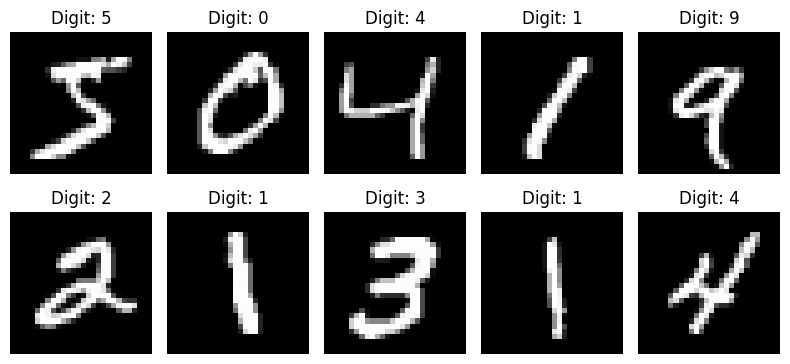

In [23]:
# 2. Load MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# 3. Display sample digit images
plt.figure(figsize=(8, 4))
for i in range(10):
  plt.subplot(2, 5, i + 1)
  plt.imshow(x_train[i], cmap="gray")
  plt.title(f"Digit: {y_train[i]}")
  plt.axis("off")
  plt.tight_layout()
plt.show()

In [24]:
# 4. Normalization pixel values from 0 - 255 to 0 -1
x_train = x_train / 255.0
x_test = x_test / 255.0

In [25]:
# 5. Build a 3 - layer neural network
model = Sequential([
  Flatten(input_shape=(28, 28)),
  Dense(128, activation="relu"),
  Dense(64, activation="relu"),
  Dense(10, activation="softmax")
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [26]:
# 6. Display network architecture
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:
# 7, Compile the model
model.compile (
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [18]:
# 8. Train the model
history = model.fit (
    x_train, y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9251 - loss: 0.2538 - val_accuracy: 0.9648 - val_loss: 0.1199
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9684 - loss: 0.1052 - val_accuracy: 0.9713 - val_loss: 0.0939
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9771 - loss: 0.0733 - val_accuracy: 0.9768 - val_loss: 0.0756
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9828 - loss: 0.0541 - val_accuracy: 0.9780 - val_loss: 0.0759
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9864 - loss: 0.0426 - val_accuracy: 0.9785 - val_loss: 0.0812


In [19]:
# 9. Evaluate the model
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test LossL:", test_loss)
print(f"Test accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9761 - loss: 0.0807
Test LossL: 0.08065665513277054
Test accuracy: 0.9761000275611877


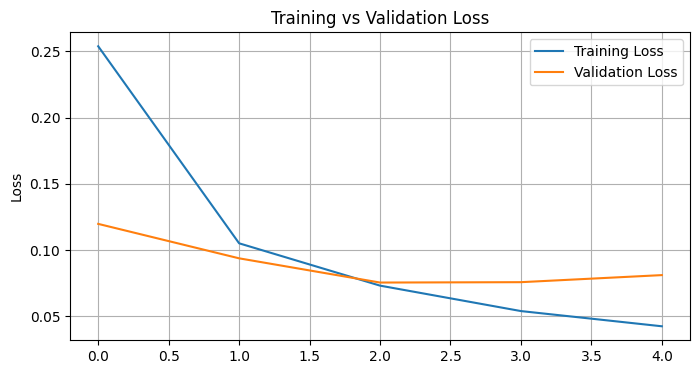

In [20]:
# 10. Visualize training and validation loss
plt.figure(figsize=(8, 4))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

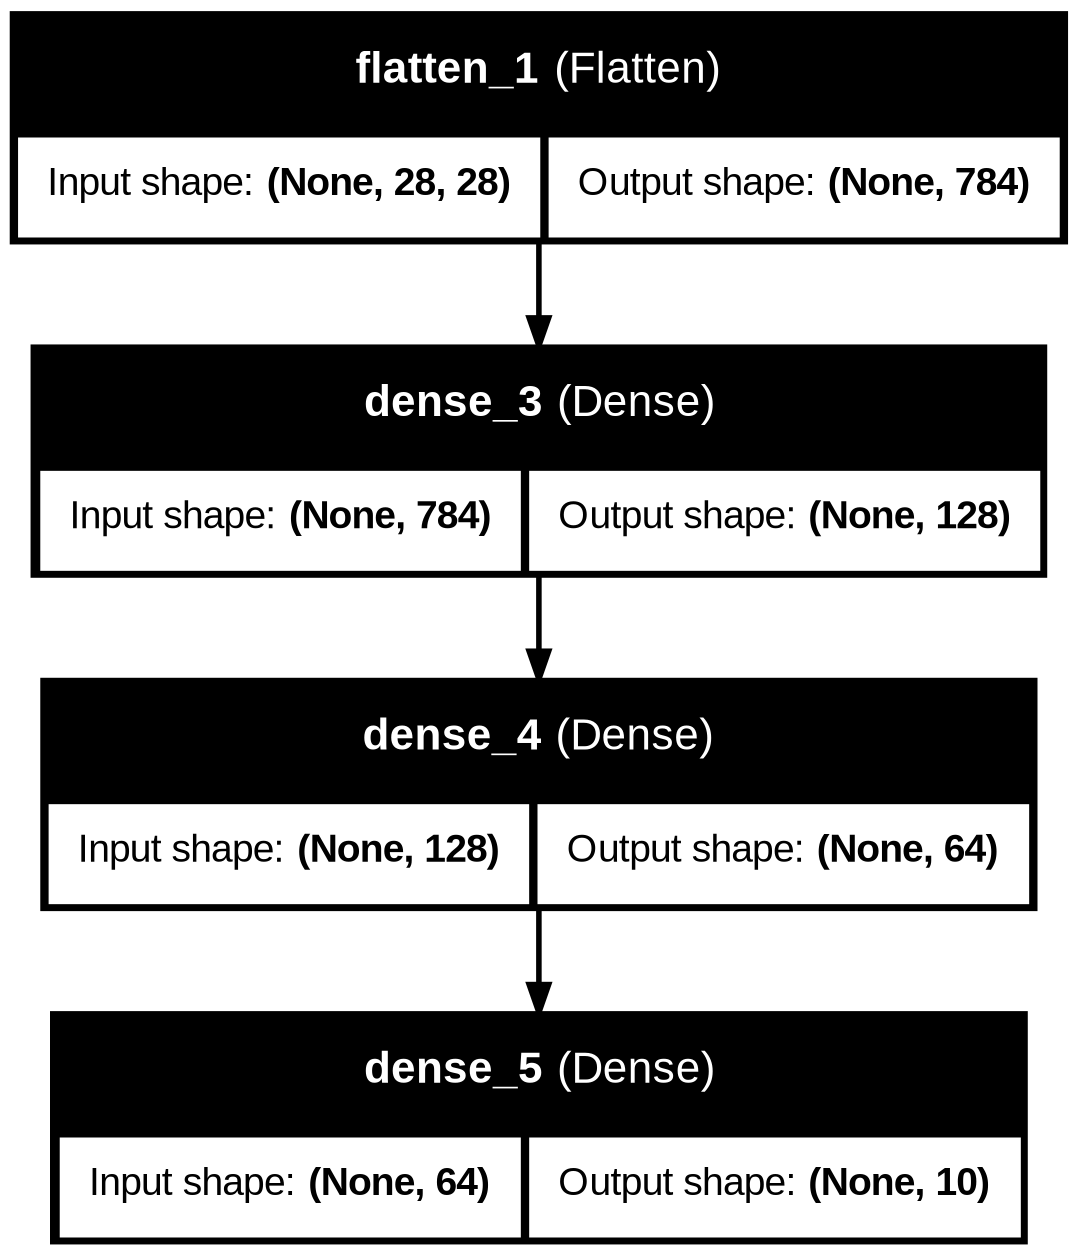

In [29]:
# 12. Visualize the neural network architecture
tf.keras.utils.plot_model(
    model,
    show_shapes=True,
    show_layer_names=True,
    to_file="dnn_architecture.png"
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step


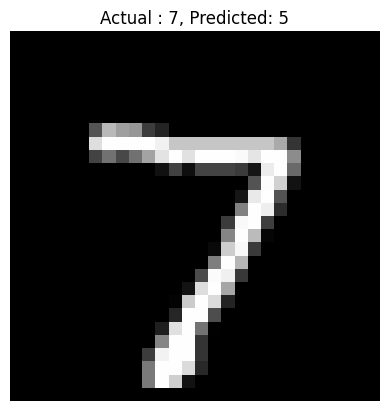

In [30]:
# 13. Predict a sample digit
predictions = model.predict(x_test[:1])
predicted_digit = np.argmax(predictions[0])

plt.imshow(x_test[0], cmap="gray")
plt.title(f"Actual : {y_test[0]}, Predicted: {predicted_digit}")
plt.axis("off")
plt.show()